<a href="https://colab.research.google.com/github/yasaswini07-m/Banking-management/blob/main/Major_Project_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
humansintheloop_semantic_segmentation_of_aerial_imagery_path = kagglehub.dataset_download('humansintheloop/semantic-segmentation-of-aerial-imagery')

print('Data source import complete.')


100%|██████████| 29.6M/29.6M [00:03<00:00, 9.48MB/s]

Extracting files...
Data source import complete.


In [ ]:
import os
import torch
import json
import glob
import numpy as np
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch.nn as nn
import torchvision.transforms.v2 as T
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision.models as models
from sklearn.model_selection import train_test_split

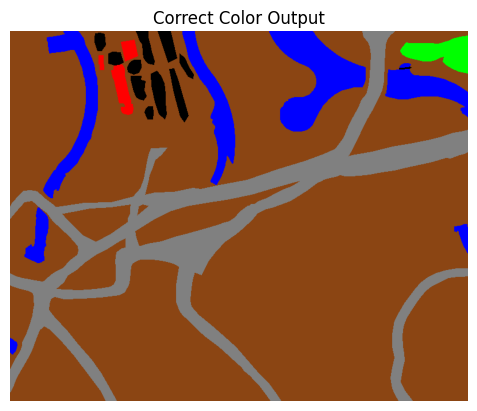

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# For demonstration, let's load a sample mask from the dataset
# Ensure 'all_mask_files' is defined from previous cells (e.g., cell 918507d9)
if 'all_mask_files' in locals() and len(all_mask_files) > 0:
    mask_path = all_mask_files[0] # Take the first mask for demonstration
else:
    # Fallback if all_mask_files is not available (should not happen if previous cells ran)
    dataset_base_path = '/root/.cache/kagglehub/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery/versions/1'
    data_root = os.path.join(dataset_base_path, 'Semantic segmentation dataset')
    tile_path = os.path.join(data_root, 'Tile 1')
    mask_path = os.path.join(tile_path, 'masks', 'image_part_001.png') # Original hardcoded path as fallback

original_mask = np.array(Image.open(mask_path).convert('RGB'))

# -----------------------------
# ORIGINAL dataset colors (DO NOT CHANGE)
# -----------------------------
original_colors = np.array([
    [226,169,41],   # class 0
    [132,41,246],   # class 1
    [110,193,228],  # class 2
    [60,16,152],    # class 3
    [254,221,58],   # class 4
    [155,155,155]   # class 5
])

# -----------------------------
# YOUR NEW COLORS
# -----------------------------
new_colors = np.array([
    [0,0,255],       # Water
    [139,69,19],     # Land
    [128,128,128],   # Road
    [255,0,0],       # Building
    [0,255,0],       # Vegetation
    [0,0,0]          # Unlabeled
])


# -----------------------------
# CONVERT ORIGINAL MASK → CLASS INDEX
# -----------------------------
h, w, _ = original_mask.shape
mask_class = np.zeros((h, w), dtype=np.uint8)

for i, color in enumerate(original_colors):
    matches = np.all(original_mask == color, axis=-1)
    mask_class[matches] = i


# -----------------------------
# APPLY NEW COLORS
# -----------------------------
colored_mask = new_colors[mask_class]


# -----------------------------
# DISPLAY
# -----------------------------

plt.imshow(colored_mask)
plt.title("Correct Color Output")
plt.axis('off')
plt.show()

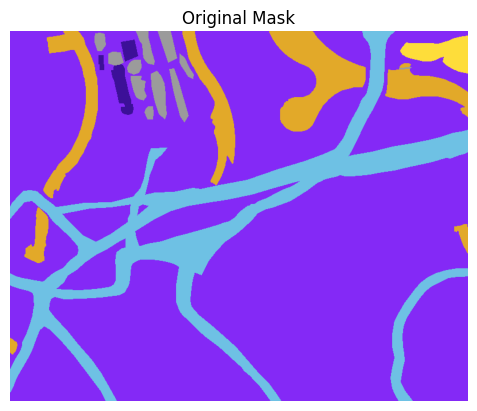

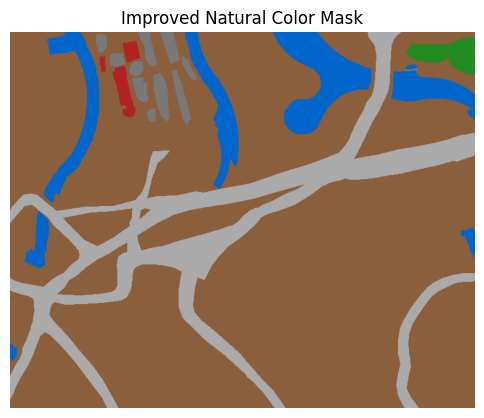

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# -----------------------------
# PATH
# -----------------------------
dataset_path = '/root/.cache/kagglehub/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery/versions/1'
data_root = os.path.join(dataset_path, 'Semantic segmentation dataset')
tile_path = os.path.join(data_root, 'Tile 1')

mask_path = os.path.join(tile_path, 'masks', 'image_part_001.png')

# -----------------------------
# LOAD MASK
# -----------------------------
original_mask = np.array(Image.open(mask_path).convert('RGB'))

plt.imshow(original_mask)
plt.title("Original Mask")
plt.axis('off')
plt.show()


# -----------------------------
# ORIGINAL DATASET COLORS (DO NOT CHANGE)
# -----------------------------
original_colors = np.array([
    [226,169,41],   # class 0
    [132,41,246],   # class 1
    [110,193,228],  # class 2
    [60,16,152],    # class 3
    [254,221,58],   # class 4
    [155,155,155]   # class 5
])


# -----------------------------
# NEW REALISTIC COLORS (SAME MEANING)
# -----------------------------
new_colors = np.array([
    [0, 102, 204],    # Water → deep blue
    [139, 94, 60],    # Land → brown
    [170, 170, 170],  # Road → light gray
    [178, 34, 34],    # Building → brick red
    [34, 139, 34],    # Vegetation → green
    [120, 120, 120]   # Unlabeled → gray
])


# -----------------------------
# RGB → CLASS INDEX
# -----------------------------
h, w, _ = original_mask.shape
mask_class = np.zeros((h, w), dtype=np.uint8)

for i, color in enumerate(original_colors):
    matches = np.all(original_mask == color, axis=-1)
    mask_class[matches] = i


# -----------------------------
# APPLY NEW COLORS
# -----------------------------
colored_mask = new_colors[mask_class]


# -----------------------------
# DISPLAY
# -----------------------------
plt.figure(figsize=(6,6))
plt.imshow(colored_mask)
plt.title("Improved Natural Color Mask")
plt.axis('off')
plt.show()

### Visualizing an Original Mask for Color Value Check

In [ ]:
import os
import torch
import json
import glob
import numpy as np
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch.nn as nn
import torchvision.transforms.v2 as T
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision.models as models
from sklearn.model_selection import train_test_split
import torchvision.tv_tensors as tv_tensors

class AerialDataset(Dataset):
    def __init__(self, image_files, mask_files, mode="train"):
        super().__init__()
        self.image_files = image_files
        self.mask_files = mask_files
        self.mode = mode

        if mode == "train":
            self.transform = T.Compose([
                # Geometric transforms - SAFE for masks with TVTensor
                T.Resize((512, 512), interpolation=T.InterpolationMode.BILINEAR),
                T.RandomHorizontalFlip(p=0.5),
                T.RandomRotation(degrees=10),

                # Photometric transforms - only apply to images automatically
                T.ColorJitter(brightness=0.2, contrast=0.2),

                # Convert and normalize
                T.ToImage(),
                T.ToDtype(torch.float32, scale=True),
                T.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225],
                ),
            ])
        else:
            self.transform = T.Compose([
                T.Resize((512, 512)),
                T.ToImage(),
                T.ToDtype(torch.float32, scale=True),
                T.Normalize(
                    mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225],
                ),
            ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = self.image_files[idx]
        mask_path = self.mask_files[idx]

        image = Image.open(img_path).convert('RGB')
        image_tvtensor = tv_tensors.Image(image)


        mask = Image.open(mask_path).convert('RGB')
        mask_np = np.array(mask)
        h, w = mask_np.shape[0], mask_np.shape[1]
        mask_classes = np.zeros((h, w), dtype=np.int64)

        for rgb, color_idx in color_rgb_to_class.items():
            matches = np.all(mask_np == rgb, axis=-1)
            mask_classes[matches] = color_idx

        mask_tvtensor = tv_tensors.Mask(mask_classes)

        if self.mode == "train":
            image_tvtensor, mask_tvtensor = self.transform(image_tvtensor, mask_tvtensor)
        else:
            # For validation/test, apply image transforms and then resize mask separately
            # to ensure its a Mask tv_tensor for potential later transforms/checks
            image_tvtensor = self.transform(image_tvtensor)
            mask_tvtensor = T.Resize((512, 512), interpolation=T.InterpolationMode.NEAREST)(mask_tvtensor)

        return image_tvtensor, mask_tvtensor

In [ ]:
color_rgb_to_class = {
    (226,169,41): 0,
    (132,41,246): 1,
    (110,193,228): 2,
    (60,16,152): 3,
    (254,221,58): 4,
    (155,155,155): 5  # Added mapping for class 5 (Unlabeled)
}

def mask_to_color(mask):
    import numpy as np
    h, w = mask.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)

    for cls, color in class_to_color_rgb.items():
        color_mask[mask == cls] = color

    return color_mask

In [ ]:
# Usage
if __name__ == "__main__":
    # Update data_root to point to the actual downloaded dataset location
    dataset_base_path = humansintheloop_semantic_segmentation_of_aerial_imagery_path
    data_root = os.path.join(dataset_base_path, 'Semantic segmentation dataset')

    def collect_files(root):
        images, masks = [], []
        for tile in range(1, 9):
            tile_path = os.path.join(root, f'Tile {tile}')
            if not os.path.exists(tile_path):
                continue
            img_files = sorted(glob.glob(os.path.join(tile_path, 'images', '*.jpg')))
            for img in img_files:
                base = os.path.basename(img).replace('.jpg', '')
                msk = os.path.join(tile_path, 'masks', f'{base}.png')
                if os.path.exists(msk):
                    images.append(img)
                    masks.append(msk)
        return images, masks

    all_image_files, all_mask_files = collect_files(data_root)
    print(f"Found {len(all_image_files)} samples")

    train_images, test_images, train_masks, test_masks = train_test_split(
        all_image_files, all_mask_files, test_size=0.2, random_state=42
    )

    # Create datasets
    train_dataset = AerialDataset(train_images, train_masks, mode='train')
    test_dataset = AerialDataset(test_images, test_masks, mode='test')

    # Create loaders
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True
    )

    test_loader = torch.utils.data.DataLoader(
        test_dataset, batch_size=8, shuffle=False, num_workers=2, pin_memory=True
    )

    # Test
    for img, mask in train_loader:
        print(f"Image: {img.shape}, Mask: {mask.shape}")
        print(f"Mask unique values: {torch.unique(mask)}")
        break

Found 72 samples
Image: torch.Size([8, 3, 512, 512]), Mask: torch.Size([8, 512, 512])
Mask unique values: tensor([0, 1, 2, 3, 4, 5])


In [ ]:
import numpy as np
print(np.unique(mask.numpy()))

[0 1 2 3 4 5]


In [ ]:
img, mask = train_dataset[50]   # try 10, 20, 50

In [ ]:
# Usage
if __name__ == "__main__":
    # Update data_root to point to the actual downloaded dataset location
    dataset_base_path = '/root/.cache/kagglehub/datasets/humansintheloop/semantic-segmentation-of-aerial-imagery/versions/1'
    data_root = os.path.join(dataset_base_path, 'Semantic segmentation dataset')

    def collect_files(root):
        images, masks = [], []
        for tile in range(1, 9):
            tile_path = os.path.join(root, f'Tile {tile}')
            if not os.path.exists(tile_path):
                continue
            img_files = sorted(glob.glob(os.path.join(tile_path, 'images', '*.jpg')))
            for img in img_files:
                base = os.path.basename(img).replace('.jpg', '')
                msk = os.path.join(tile_path, 'masks', f'{base}.png')
                if os.path.exists(msk):
                    images.append(img)
                    masks.append(msk)
        return images, masks

    all_image_files, all_mask_files = collect_files(data_root)
    print(f"Found {len(all_image_files)} samples")

    train_images, test_images, train_masks, test_masks = train_test_split(
        all_image_files, all_mask_files, test_size=0.2, random_state=42
    )

    # Create datasets
    train_dataset = AerialDataset(train_images, train_masks, mode='train')
    test_dataset = AerialDataset(test_images, test_masks, mode='test')

    # Create loaders
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True
    )

    test_loader = torch.utils.data.DataLoader(
        test_dataset, batch_size=8, shuffle=False, num_workers=2, pin_memory=True
    )

    # Test
    for img, mask in train_loader:
        print(f"Image: {img.shape}, Mask: {mask.shape}")
        print(f"Mask unique values: {torch.unique(mask)}")
        break

Found 72 samples
Image: torch.Size([8, 3, 512, 512]), Mask: torch.Size([8, 512, 512])
Mask unique values: tensor([0, 1, 2, 3, 4, 5])


In [ ]:
# how do i check?
# mask = Image.open('mask.png')
# mask_np = np.array(mask)

#mask_np.shape = (256, 256)       # Single-channel (PASCAL VOC style)
#mask_np.shape = (256, 256, 3)    # RGB 3-channel (Aerial style)
#mask_np.shape = (256, 256, 4)    # RGBA (with transparency)

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)

In [ ]:
class UNetResNet34(nn.Module):
    def __init__(self, in_channels=3, out_channels=6, pretrained=True):
        super().__init__()

        weights = 'IMAGENET1K_V1' if pretrained else None
        resnet = models.resnet34(weights=weights)

        # Freeze early layers if desired
        # for param in resnet.parameters():
        #     param.requires_grad = False

        # Encoder - ResNet34 layers
        # ResNet34 structure:
        # conv1: 64, /2
        # layer1: 64, /4
        # layer2: 128, /8
        # layer3: 256, /16
        # layer4: 512, /32

        self.initial = nn.Sequential(
            resnet.conv1,
            resnet.bn1,
            resnet.relu,
        )  # [B, 64, H/2, W/2]

        self.pool = resnet.maxpool  # [B, 64, H/4, W/4]
        self.encoder1 = resnet.layer1  # [B, 64, H/4, W/4]
        self.encoder2 = resnet.layer2  # [B, 128, H/8, W/8]
        self.encoder3 = resnet.layer3  # [B, 256, H/16, W/16]
        self.encoder4 = resnet.layer4  # [B, 512, H/32, W/32]

        # Bottleneck
        self.bottleneck = DoubleConv(512, 512)

        # Decoder
        self.upconv4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.decoder4 = DoubleConv(512, 256)  # 256 + 256

        self.upconv3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.decoder3 = DoubleConv(256, 128)  # 128 + 128

        self.upconv2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.decoder2 = DoubleConv(128, 64)   # 64 + 64

        self.upconv1 = nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2)
        self.decoder1 = DoubleConv(128, 64)   # 64 + 64 (from initial)

        # Final output
        self.upconv0 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.final_conv = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        initial = self.initial(x)  # [B, 64, H/2, W/2]
        e1 = self.encoder1(self.pool(initial))  # [B, 64, H/4, W/4]
        e2 = self.encoder2(e1)  # [B, 128, H/8, W/8]
        e3 = self.encoder3(e2)  # [B, 256, H/16, W/16]
        e4 = self.encoder4(e3)  # [B, 512, H/32, W/32]

        # Bottleneck
        bottleneck = self.bottleneck(e4)

        # Decoder with skip connections
        d4 = self.upconv4(bottleneck)
        d4 = torch.cat([d4, e3], dim=1)
        d4 = self.decoder4(d4)

        d3 = self.upconv3(d4)
        d3 = torch.cat([d3, e2], dim=1)
        d3 = self.decoder3(d3)

        d2 = self.upconv2(d3)
        d2 = torch.cat([d2, e1], dim=1)
        d2 = self.decoder2(d2)

        d1 = self.upconv1(d2)
        d1 = torch.cat([d1, initial], dim=1)
        d1 = self.decoder1(d1)

        # Final upsampling to original size
        d0 = self.upconv0(d1)
        output = self.final_conv(d0)

        return output

In [ ]:
class FocalLoss(nn.Module):
    """
    Focal Loss for Dense Prediction (Segmentation)
    Focuses learning on hard examples and down-weights easy background pixels
    """
    def __init__(self, alpha=1.0, gamma=2.0, ignore_index=255):
        super().__init__()
        self.alpha = alpha  # Weighting factor
        self.gamma = gamma  # Focusing parameter (higher = more focus on hard examples)
        self.ignore_index = ignore_index

    def forward(self, inputs, targets):
        """
        Args:
            inputs: [B, C, H, W] raw logits
            targets: [B, H, W] class indices
        """
        # Get log probabilities (numerically stable)
        log_probs = F.log_softmax(inputs, dim=1)

        # Gather log probs for target classes [B, H, W]
        targets = targets.unsqueeze(1)  # [B, 1, H, W]
        log_pt = torch.gather(log_probs, 1, targets).squeeze(1)  # [B, H, W]
        pt = torch.exp(log_pt)  # Probability of correct class

        # Create mask for valid pixels (ignore 255)
        mask = (targets.squeeze(1) != self.ignore_index).float()

        # Focal weight: (1 - p_t)^gamma
        focal_weight = self.alpha * (1 - pt) ** self.gamma

        # Apply focal weighting to CE loss
        loss = -focal_weight * log_pt

        # Apply mask and average
        loss = (loss * mask).sum() / (mask.sum() + 1e-6)

        return loss


class DiceLoss(nn.Module):
    """
    Dice Loss for overlap maximization
    """
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, inputs, targets):
        inputs = F.softmax(inputs, dim=1)
        num_classes = inputs.shape[1]

        # One-hot encode targets [B, H, W] -> [B, C, H, W]
        targets_one_hot = F.one_hot(targets, num_classes).permute(0, 3, 1, 2).float()

        # Flatten spatial dimensions
        inputs_flat = inputs.reshape(inputs.size(0), num_classes, -1)
        targets_flat = targets_one_hot.reshape(targets_one_hot.size(0), num_classes, -1)

        intersection = (inputs_flat * targets_flat).sum(dim=2)
        cardinality = inputs_flat.sum(dim=2) + targets_flat.sum(dim=2)

        dice = (2. * intersection + self.smooth) / (cardinality + self.smooth)
        return 1 - dice.mean()


# Combined Loss: Focal + Dice
class FocalDiceLoss(nn.Module):
    def __init__(self, focal_weight=0.5, dice_weight=0.5, gamma=2.0, alpha=1.0):
        """
        Combined Focal and Dice Loss

        Args:
            focal_weight: Weight for Focal Loss component
            dice_weight: Weight for Dice Loss component
            gamma: Focal loss focusing parameter (2.0 is standard, 1.0-3.0 typical range)
            alpha: Focal loss balancing parameter
        """
        super().__init__()
        self.focal = FocalLoss(alpha=alpha, gamma=gamma)
        self.dice = DiceLoss()
        self.focal_weight = focal_weight
        self.dice_weight = dice_weight

    def forward(self, inputs, targets):
        loss_focal = self.focal(inputs, targets)
        loss_dice = self.dice(inputs, targets)

        return self.focal_weight * loss_focal + self.dice_weight * loss_dice


# Alternative: Adaptive weighting based on epoch (optional advanced version)
class AdaptiveFocalDiceLoss(nn.Module):
    def __init__(self, initial_focal_weight=0.3, final_focal_weight=0.7, total_epochs=50):
        super().__init__()
        self.focal = FocalLoss(gamma=2.0)
        self.dice = DiceLoss()
        self.initial_fw = initial_focal_weight
        self.final_fw = final_focal_weight
        self.total_epochs = total_epochs
        self.current_epoch = 0
        self.current_focal_w = initial_focal_weight

    def set_epoch(self, epoch):
        """Update weighting based on current epoch and return current focal weight"""
        self.current_epoch = epoch
        # Linear interpolation: starts at initial_fw, reaches final_fw at 60% of training
        progress = min(epoch / max(self.total_epochs * 0.6, 1), 1.0)  # Avoid div by zero
        self.current_focal_w = self.initial_fw + (self.final_fw - self.initial_fw) * progress
        return self.current_focal_w  # CRITICAL: Must return the value

    def forward(self, inputs, targets):
        dice_w = 1.0 - self.current_focal_w
        loss_focal = self.focal(inputs, targets)
        loss_dice = self.dice(inputs, targets)
        total_loss = self.current_focal_w * loss_focal + dice_w * loss_dice
        return total_loss, loss_focal, loss_dice


In [ ]:
# Metrics Calculation
def calculate_iou(pred, target, num_classes=6, ignore_index=255):
    """Calculate mean IoU and per-class IoU"""
    ious = []
    pred = pred.argmax(dim=1)  # [B, H, W]

    for cls in range(num_classes):
        pred_mask = (pred == cls)
        target_mask = (target == cls)

        intersection = (pred_mask & target_mask).sum().float()
        union = (pred_mask | target_mask).sum().float()

        if union == 0:
            ious.append(float('nan'))  # Class not present
        else:
            ious.append((intersection / union).item())

    valid_ious = [iou for iou in ious if not torch.isnan(torch.tensor(iou))]
    mean_iou = sum(valid_ious) / len(valid_ious) if valid_ious else 0

    return mean_iou, ious

In [ ]:
torch.cuda.empty_cache()       # clear reserved memory

In [ ]:
# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Model
model = UNetResNet34(in_channels=3, out_channels=6, pretrained=True).to(device)
criterion = AdaptiveFocalDiceLoss(
    initial_focal_weight=0.3,
    final_focal_weight=0.7,
    total_epochs=50
)
    # If vehicles are still being missed, increase beta further:
    # criterion = TverskyLoss(alpha=0.2, beta=0.8)  # Aggressive small object detection

# Optimizer & Scheduler
optimizer = torch.optim.AdamW([
    {'params': [p for n, p in model.named_parameters() if 'layer' in n], 'lr': 1e-5},
    {'params': [p for n, p in model.named_parameters() if 'layer' not in n], 'lr': 1e-4}
], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-7
)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 154MB/s]


In [ ]:
from tqdm import tqdm
num_epochs = 50
best_miou = 0.0

In [ ]:
import torch
from torch.cuda.amp import autocast, GradScaler
from tqdm import tqdm

# Initialize GradScaler for mixed precision
scaler = GradScaler()

# Training loop
for epoch in range(num_epochs):
    # CRITICAL: Update loss weighting for this epoch
    current_focal_w = criterion.set_epoch(epoch)
    current_dice_w = 1.0 - current_focal_w
    print(f"\nEpoch {epoch+1}/{num_epochs} - Loss Weights: Focal={current_focal_w:.2f}, Dice={current_dice_w:.2f}")

    # Training Phase
    model.train()
    train_loss = 0
    train_focal = 0
    train_dice = 0

    pbar = tqdm(train_loader, desc='Training')
    for images, masks in pbar:
        images = images.to(device)
        masks = masks.to(device).squeeze(1).long()

        optimizer.zero_grad()

        with autocast():
            outputs = model(images)
            loss, loss_f, loss_d = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        train_focal += loss_f.item()
        train_dice += loss_d.item()
        pbar.set_postfix({
            'loss': loss.item(),
            'focal': loss_f.item(),
            'dice': loss_d.item()
        })

    avg_train_loss = train_loss / len(train_loader)
    avg_train_focal = train_focal / len(train_loader)
    avg_train_dice = train_dice / len(train_loader)

    # Validation Phase
    model.eval()
    val_loss = 0
    intersection = torch.zeros(6).to(device)
    union = torch.zeros(6).to(device)

    with torch.no_grad():
        for images, masks in test_loader:
            images = images.to(device)
            masks = masks.to(device).squeeze(1).long()

            with autocast():
                outputs = model(images)
                loss, _, _ = criterion(outputs, masks)
                val_loss += loss.item()

            # Calculate IoU
            preds = outputs.argmax(dim=1)
            for cls in range(6):
                pred_mask = (preds == cls)
                true_mask = (masks == cls)
                intersection[cls] += (pred_mask & true_mask).sum()
                union[cls] += (pred_mask | true_mask).sum()

    avg_val_loss = val_loss / len(test_loader)
    iou_per_class = intersection / (union + 1e-6)
    miou = iou_per_class.mean().item()

    # Step scheduler
    scheduler.step(miou)

    # Print detailed results
    print(f"Epoch {epoch+1} Summary:")
    print(f"  Train Loss: {avg_train_loss:.4f} (Focal: {avg_train_focal:.4f}, Dice: {avg_train_dice:.4f})")
    print(f"  Val Loss: {avg_val_loss:.4f}, mIoU: {miou:.4f}")
    print(f"  IoU per class: {iou_per_class.cpu().numpy()}")

    # Save best model
    if miou > best_miou:
        best_miou = miou
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'miou': best_miou,
            'focal_weight': current_focal_w
        }, 'best_adaptive_model.pth')
        print(f"  ✓ Saved best model with mIoU={best_miou:.4f}")

    # Clear cache
    torch.cuda.empty_cache()

/tmp/ipykernel_496/2613234862.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Epoch 1/50 - Loss Weights: Focal=0.30, Dice=0.70


Training:   0%|          | 0/8 [00:00<?, ?it/s]/tmp/ipykernel_496/2613234862.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Training: 100%|██████████| 8/8 [00:19<00:00,  2.43s/it, loss=0.928, focal=1.08, dice=0.864]
/tmp/ipykernel_496/2613234862.py:60: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1 Summary:
  Train Loss: 0.9629 (Focal: 1.1605, Dice: 0.8782)
  Val Loss: 0.9861, mIoU: 0.0440
  IoU per class: [1.21787526e-01 1.06528341e-05 0.00000000e+00 1.42063111e-01
 0.00000000e+00 0.00000000e+00]
  ✓ Saved best model with mIoU=0.0440

Epoch 2/50 - Loss Weights: Focal=0.31, Dice=0.69


Training: 100%|██████████| 8/8 [00:18<00:00,  2.27s/it, loss=0.893, focal=0.98, dice=0.853]


...

Epoch 48 Summary:
  Train Loss: 0.3593 (Focal: 0.2488, Dice: 0.6170)
  Val Loss: 0.3717, mIoU: 0.6021
  IoU per class: [0.91012156 0.74833477 0.46716312 0.70196664 0.78529406 0.        ]

Epoch 49/50 - Loss Weights: Focal=0.70, Dice=0.30


Training: 100%|██████████| 8/8 [00:17<00:00,  2.25s/it, loss=0.405, focal=0.328, dice=0.584]


Epoch 49 Summary:
  Train Loss: 0.3469 (Focal: 0.2326, Dice: 0.6138)
  Val Loss: 0.3716, mIoU: 0.6036
  IoU per class: [0.90199673 0.74770653 0.47511843 0.70317125 0.7933809  0.        ]
  ✓ Saved best model with mIoU=0.6036

Epoch 50/50 - Loss Weights: Focal=0.70, Dice=0.30


Training: 100%|██████████| 8/8 [00:18<00:00,  2.28s/it, loss=0.81, focal=0.806, dice=0.817]


Epoch 50 Summary:
  Train Loss: 0.3837 (Focal: 0.2782, Dice: 0.6300)
  Val Loss: 0.3672, mIoU: 0.5996
  IoU per class: [0.9006376  0.738273   0.47511625 0.6979205  0.78572255 0.        ]


<Figure size 1200x1200 with 0 Axes>

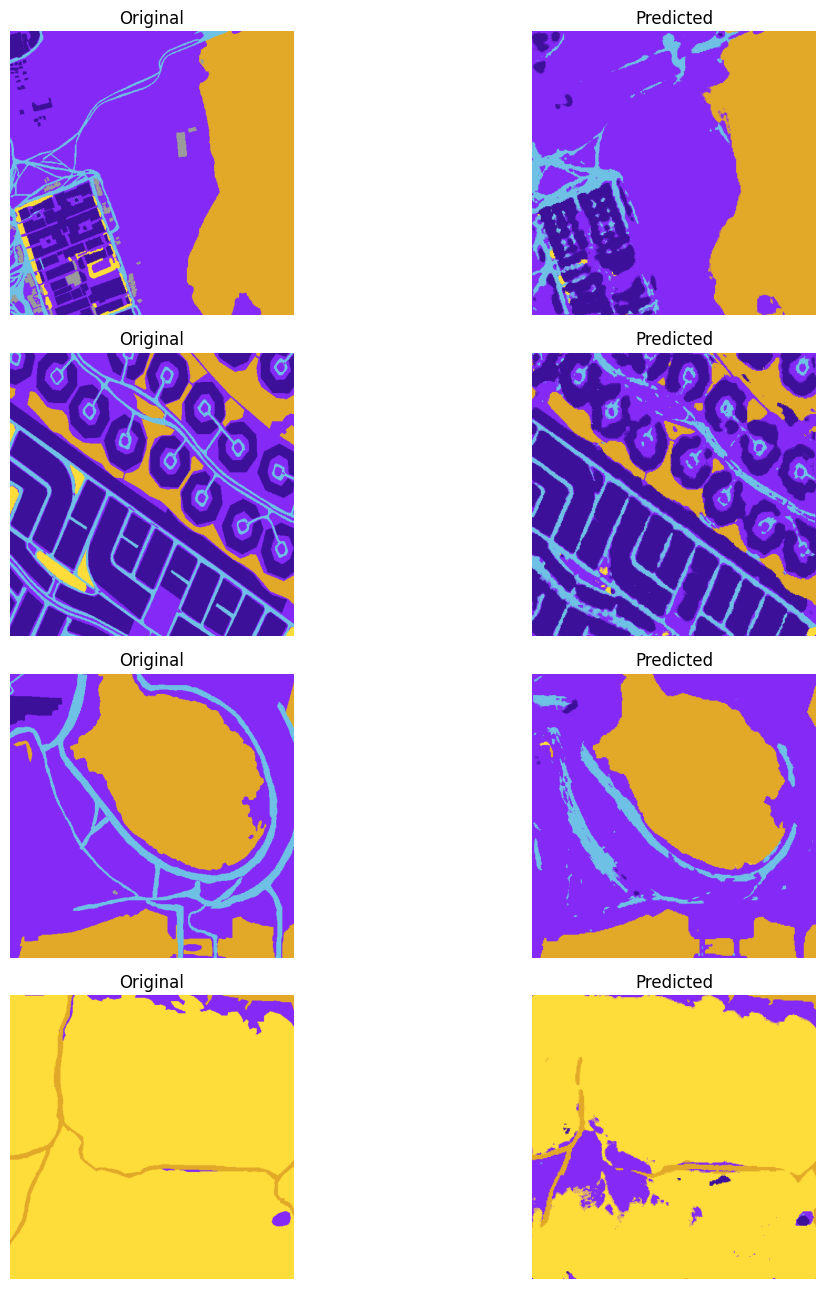

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random # Import the random module

# Plot predictions
model.eval()


num_images = 4  # how many images to show
indices = random.sample(range(len(test_dataset)), num_images)

images, masks = [], []
for idx in indices:
    img, mask = test_dataset[idx]
    images.append(img.unsqueeze(0))  # add batch dim
    masks.append(mask)

X_batch = torch.cat(images).to(device)
y_batch = torch.stack(masks).to(device)

with torch.no_grad():
    output = model(X_batch)
    preds = output.argmax(dim=1).cpu().numpy()
    targets = y_batch.cpu().numpy()

# Define class_to_color_rgb by reversing color_rgb_to_class
class_to_color_rgb = {v: k for k, v in color_rgb_to_class.items()}

# Lookup table: class index -> RGB
lut = np.array([v for k, v in class_to_color_rgb.items()], dtype=np.uint8)

# Use num_images instead of BATCH_SIZE for plotting
plt.figure(figsize=(12, 3 * num_images))

# No need to redefine BATCH_SIZE here, use num_images directly
# BATCH_SIZE = min(BATCH_SIZE, len(preds))  # ensure we don’t exceed length

plt.figure(figsize=(13, 13))

for i in range(num_images):
    pred = preds[i]
    target = targets[i]

    plt.subplot(num_images, 2, 2*i + 1)
    plt.title("Original")
    plt.imshow(lut[target])
    plt.axis('off')

    plt.subplot(num_images, 2, 2*i + 2)
    plt.title("Predicted")
    plt.imshow(lut[pred])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import gradio as gr
from torchvision.transforms import ToPILImage

# Ensure the model is loaded and on the correct device if not already
# model = UNetResNet34(in_channels=3, out_channels=6, pretrained=True).to(device)
# model.load_state_dict(torch.load('best_adaptive_model.pth')['model_state_dict'])
# model.eval()

In [ ]:
def predict_segmentation(input_image_pil):
    # Apply the same transformations as the test_dataset, excluding tv_tensors
    # and ensuring the output is a tensor ready for the model.
    transform = T.Compose([
        T.Resize((512, 512)),
        T.ToImage(),
        T.ToDtype(torch.float32, scale=True),
        T.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        ),
    ])

    # Convert PIL image to tensor, then add batch dimension
    input_tensor = transform(input_image_pil).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        preds = output.argmax(dim=1).cpu().numpy()

    # Get the first (and only) prediction from the batch
    predicted_mask_indices = preds[0]

    # Convert class indices back to RGB image using the lookup table (lut)
    # lut was defined in an earlier cell: lut = np.array([v for k, v in class_to_color_rgb.items()], dtype=np.uint8)
    segmented_image_rgb = lut[predicted_mask_indices]

    # Convert numpy array back to PIL Image for Gradio
    return Image.fromarray(segmented_image_rgb)

In [ ]:
interface = gr.Interface(
    fn=predict_segmentation,
    inputs=gr.Image(type="pil", label="Upload Image"),
    outputs=gr.Image(type="pil", label="Segmented Mask"),
    title="U-Net ResNet34 Semantic Segmentation of Aerial Imagery",
    description="Upload an aerial image to get its semantic segmentation mask. The model segments water, land, road, building, vegetation, and unlabeled areas."
)

interface.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ca1021e78453250ec2.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Set model to evaluation mode
model.eval()

all_preds = []
all_targets = []

# Iterate over the test set to collect predictions and ground truths
with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device).squeeze(1).long()

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.append(preds.cpu().numpy().flatten())
        all_targets.append(masks.cpu().numpy().flatten())

# Concatenate all predictions and targets
all_preds = np.concatenate(all_preds)
all_targets = np.concatenate(all_targets)

# Calculate the confusion matrix
# We need to filter out ignore_index if it was used, but for now we assume 6 classes 0-5
cm = confusion_matrix(all_targets, all_preds, labels=np.arange(6))

# Define class names for better readability
class_names = ['Water', 'Land', 'Road', 'Building', 'Vegetation', 'Unlabeled']

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Semantic Segmentation')
plt.show()